<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/code/01NAEX_Ex08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 08: Two-level fractional factorial designs

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 8.
Problem numbers follow the 8th edition.

## Learning goals

* Construct a $2^{k-p}$ fractional factorial design from a basic design and design generators.
* Find the complete defining relation, the alias structure and the resolution of a design.
* Analyze a fractional factorial: effects of the alias chains, normal and half-normal plots, projection into a full factorial,
  reduced model, residuals, location and dispersion effects.
* Verify an interpretation by a confirmation run (prediction interval) and by the alternate fraction.
* Compute the alias matrix $A = (X_1^TX_1)^{-1}X_1^TX_2$.
* Compare designs of the same resolution by their word length pattern (minimum aberration) and run a fraction in blocks.
* Use the single-factor and the full fold-over of a resolution III design to separate aliased effects.

## Setup

Run this cell first. Besides the standard imports it defines helper functions used below:

* `multiply()` - product of effects modulo 2 (squared letters cancel), e.g. `multiply("A", "ABCD") == "BCD"` (as in Exercise 7).
* `defining_relation()` - all $2^p - 1$ words of the complete defining relation for given generators.
* `aliases()` - the aliases of an effect; `alias_chains()` - the alias structure up to a given order of interactions.
* `fractional_design()` - a $2^{k-p}$ design: full factorial in the basic factors (standard order) plus the added factors.
* `effect()` - effect estimate of a column product, contrast$/(N/2)$, for any two-level design without replicates in the
  formula (replicates are fine: all rows are used).
* `effect_plot()` - normal (or half-normal) probability plot of the effects with a reference line through the small effects.
* `alias_matrix()`, `wlp()` - the alias matrix and the word length pattern.
* `design_from_runs()` - factor columns coded $\pm1$ from treatment combinations such as `"abe"` (used in the assignment).

In [1]:
import itertools
from functools import reduce

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/"


def multiply(*effects):
    """Product of effects modulo 2 (squared letters cancel): multiply("A", "ABCD") -> "BCD"."""
    letters = reduce(lambda s, e: s ^ set(e), effects, set()) - {"I"}
    return "".join(sorted(letters)) or "I"


def defining_relation(generators):
    """All 2^p - 1 words: the generators and all their products, sorted by length."""
    words = [multiply(*c) for r in range(1, len(generators) + 1)
             for c in itertools.combinations(generators, r)]
    return sorted(words, key=lambda w: (len(w), w))


def aliases(effect, words):
    """Aliases of an effect: the effect times every word of the defining relation."""
    return [multiply(effect, w) for w in words]


def alias_chains(factors, generators, max_order=2):
    """Alias chains of all effects up to max_order (each chain listed once), ignoring longer interactions."""
    words = defining_relation(generators)
    seen, chains = set(), []
    for r in range(1, max_order + 1):
        for c in itertools.combinations(factors, r):
            e = "".join(c)
            chain = [e] + aliases(e, words)
            key = frozenset(chain)
            if key in seen:
                continue
            seen.add(key)
            short = [a for a in chain if len(a) <= max_order]
            chains.append(" = ".join(sorted(short, key=lambda s: (len(s), s))))
    return chains


def fractional_design(basic, added):
    """2^(k-p) design. basic: string of the basic factors, e.g. "ABCD"; added: dict, e.g. {"E": "ABC", "F": "-BCD"}.

    The basic design is a full factorial in standard order (A changes fastest), columns coded -1/+1.
    A leading minus in a generator gives the corresponding alternate fraction.
    """
    d = pd.DataFrame(itertools.product([-1, 1], repeat=len(basic)), columns=list(basic[::-1]))[list(basic)]
    for f, g in added.items():
        sign = -1 if g.startswith("-") else 1
        d[f] = sign * d[list(g.lstrip("-"))].prod(axis=1)
    letters = list(basic) + list(added)
    d.insert(0, "run", d.apply(lambda r: "".join(c.lower() for c in letters if r[c] > 0) or "(1)", axis=1))
    return d


def effect(df, w, y="y"):
    """Effect estimate of the column product w (e.g. "AC"): contrast / (N/2)."""
    s = df[list(w)].prod(axis=1)
    return 2 * (s * df[y]).sum() / len(df)


def effect_plot(effects, half=False, n_label=5, ax=None, title=None):
    """Normal (Daniel) or half-normal probability plot of the effects (a pd.Series indexed by the effect names)."""
    e = (effects.abs() if half else effects).sort_values()
    m = len(e)
    p = (np.arange(1, m + 1) - 0.5) / m
    q = stats.halfnorm.ppf(p) if half else stats.norm.ppf(p)
    x = e.to_numpy(dtype=float)
    small = np.argsort(np.abs(x))[: max(m // 2, 2)]
    if half:
        b, a = (x[small] @ q[small]) / (q[small] @ q[small]), 0.0
        qq = np.linspace(0, q.max(), 50)
    else:
        b, a = np.polyfit(q[small], x[small], 1)
        qq = np.linspace(q.min(), q.max(), 50)
    xl = a + b * qq
    keep = (xl >= x.min() - 0.1 * np.ptp(x)) & (xl <= x.max() + 0.1 * np.ptp(x))
    if ax is None:
        ax = plt.subplots(figsize=(5, 4))[1]
    ax.scatter(x, q, color="k", s=20, zorder=3)
    ax.plot(xl[keep], qq[keep], color="tab:red", lw=1)
    largest = effects.abs().sort_values().index[-n_label:] if n_label else []
    for name, xi, qi in zip(e.index, x, q):
        if name in largest:
            ax.annotate(name, (xi, qi), xytext=(-6, 5), textcoords="offset points", ha="right", fontsize=9)
    ax.margins(x=0.12, y=0.12)
    ax.set_xlabel("|effect|" if half else "effect")
    ax.set_ylabel("half-normal quantile" if half else "normal quantile")
    ax.set_title(title or ("Half-normal plot of effects" if half else "Normal probability plot of effects"), fontsize=10)
    ax.grid(alpha=0.3)
    return ax


def alias_matrix(X1, X2):
    """Alias matrix A = (X1'X1)^{-1} X1'X2: E(b1) = beta1 + A beta2 if the effects in X2 are omitted from the model."""
    return np.linalg.solve(X1.T @ X1, X1.T @ X2)


def design_from_runs(runs, factors):
    """Treatment combinations and factor columns coded -1/+1, e.g. design_from_runs(["e", "ab"], "ABCDE")."""
    d = pd.DataFrame({"run": runs})
    for f in factors:
        d[f] = np.where(d["run"].str.contains(f.lower()), 1, -1)
    return d


def wlp(generators, k):
    """Word length pattern (A3, A4, ..., Ak): number of words of each length in the defining relation."""
    lens = [len(w) for w in defining_relation(generators)]
    return [lens.count(L) for L in range(3, k + 1)]

## 1. Constructing fractions, defining relation, aliases and resolution

**Construction:** write down the full factorial in $k-p$ basic factors and add $p$ factors whose levels are products of the
basic columns (the design generators). For the one-half fraction of the $2^3$ design use $C = AB$, i.e. $I = ABC$; the
alternate fraction is $C = -AB$, $I = -ABC$.

In [2]:
principal = fractional_design("AB", {"C": "AB"})       # I = ABC
alternate = fractional_design("AB", {"C": "-AB"})      # I = -ABC
display(principal, alternate)

,run,A,B,C
0,c,-1,-1,1
1,a,1,-1,-1
2,b,-1,1,-1
3,abc,1,1,1


,run,A,B,C
0,(1),-1,-1,-1
1,ac,1,-1,1
2,bc,-1,1,1
3,ab,1,1,-1


The **complete defining relation** contains the generators and all their products (generalized interactions). The
**resolution** is the length of the shortest word. Aliases of an effect: multiply it by every word.

In [3]:
for gens in (["ABC"], ["ABCD"], ["ABCDE"], ["ABCE", "BCDF"], ["ABD", "ACE", "BCF", "ABCG"]):
    words = defining_relation(gens)
    print(f"generators {gens}: I = {' = '.join(words)}  -> resolution {min(map(len, words))}")

generators ['ABC']: I = ABC  -> resolution 3
generators ['ABCD']: I = ABCD  -> resolution 4
generators ['ABCDE']: I = ABCDE  -> resolution 5
generators ['ABCE', 'BCDF']: I = ABCE = ADEF = BCDF  -> resolution 4
generators ['ABD', 'ACE', 'BCF', 'ABCG']: I = ABD = ACE = AFG = BCF = BEG = CDG = DEF = ABCG = ABEF = ACDF = ADEG = BCDE = BDFG = CEFG = ABCDEFG  -> resolution 3


In [4]:
words = defining_relation(["ABCE", "BCDF"])            # the 2^(6-2)_IV design of Lecture 8
for e in ["A", "AB", "AE"]:
    print(e, "=", " = ".join(aliases(e, words)))
print()
print("Alias chains (main effects and two-factor interactions only):")
for ch in alias_chains("ABCDEF", ["ABCE", "BCDF"]):
    print("  ", ch)

A = BCE = DEF = ABCDF
AB = CE = BDEF = ACDF
AE = BC = DF = ABCDEF

Alias chains (main effects and two-factor interactions only):
   A
   B
   C
   D
   E
   F
   AB = CE
   AC = BE
   AD = EF
   AE = BC = DF
   AF = DE
   BD = CF
   BF = CD


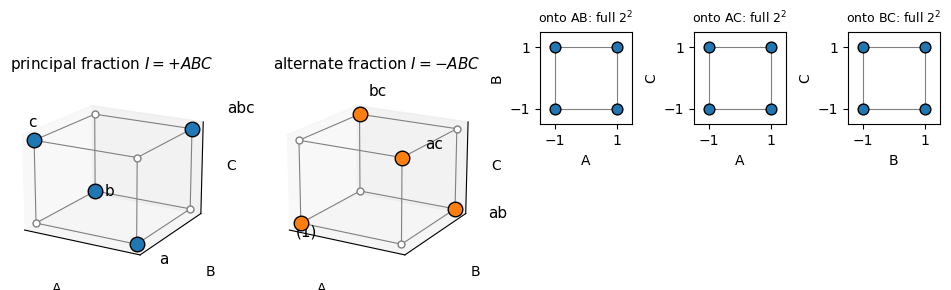

In [5]:
# Figure of Lecture 8: the two half fractions of the 2^3 design and the projection property
def cube_edges(ax):
    for e_ in itertools.product([-1, 1], repeat=3):
        for j in range(3):
            if e_[j] == -1:
                e2 = list(e_); e2[j] = 1
                ax.plot(*zip(e_, e2), color="grey", lw=0.8)


fig = plt.figure(figsize=(12, 4.3))
gs = fig.add_gridspec(2, 5, width_ratios=[2.2, 2.2, 1, 1, 1], hspace=0.55, wspace=0.45)
for j, (frac, ttl, col) in enumerate([(principal, "principal fraction $I=+ABC$", "tab:blue"),
                                      (alternate, "alternate fraction $I=-ABC$", "tab:orange")]):
    a3 = fig.add_subplot(gs[:, j], projection="3d")
    cube_edges(a3)
    on = set(map(tuple, frac[["A", "B", "C"]].to_numpy()))
    for x in itertools.product([-1, 1], repeat=3):
        a3.scatter(*x, s=110 if x in on else 25, color=col if x in on else "white",
                   edgecolor="k" if x in on else "grey", depthshade=False)
    for _, r in frac.iterrows():
        a3.text(r.A * 1.25 + 0.3, r.B * 1.25, r.C * 1.3 + 0.1, r.run, fontsize=11)
    a3.set_xlabel("A"); a3.set_ylabel("B"); a3.set_zlabel("C", labelpad=-8)
    a3.set_xticks([]); a3.set_yticks([]); a3.set_zticks([])
    a3.view_init(elev=18, azim=-60); a3.set_title(ttl, fontsize=11)
for j, (f1, f2) in enumerate([("A", "B"), ("A", "C"), ("B", "C")]):
    a2 = fig.add_subplot(gs[0, 2 + j])
    a2.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], color="grey", lw=0.8)
    a2.scatter(principal[f1], principal[f2], s=60, color="tab:blue", edgecolor="k", zorder=3)
    a2.set_xlim(-1.5, 1.5); a2.set_ylim(-1.5, 1.5); a2.set_aspect("equal")
    a2.set_xticks([-1, 1]); a2.set_yticks([-1, 1]); a2.set_xlabel(f1); a2.set_ylabel(f2)
    a2.set_title(f"onto {f1}{f2}: full $2^2$", fontsize=9)
plt.show()

## 2. Lecture example: the $2^{4-1}_{IV}$ filtration rate experiment (Example 8.1)

The filtration rate experiment of Exercise 6 (Example 6.2): temperature ($A$), pressure ($B$), concentration of formaldehyde
($C$), stirring rate ($D$); in the full $2^4$ design the active effects were $A$, $C$, $D$, $AC$ and $AD$. What if only the
half fraction with $I = ABCD$ had been run? We take the 8 runs of this fraction from the full data.

In [6]:
full = pd.read_csv(URL + "Pilot_Plant_Filtration_Rate_Experiment.csv", sep=";")
d = fractional_design("ABC", {"D": "ABC"})                    # generator D = ABC, I = ABCD
d = d.merge(full, on=["A", "B", "C", "D"]).rename(columns={"Rate": "y"})
d

,run,A,B,C,D,y
0,(1),-1,-1,-1,-1,45
1,ad,1,-1,-1,1,100
2,bd,-1,1,-1,1,45
3,ab,1,1,-1,-1,65
4,cd,-1,-1,1,1,75
5,ac,1,-1,1,-1,60
6,bc,-1,1,1,-1,80
7,abcd,1,1,1,1,96


In [7]:
words = defining_relation(["ABCD"])
e81 = pd.Series({f"{w} + {aliases(w, words)[0]}": effect(d, w) for w in ["A", "B", "C", "D", "AB", "AC", "AD"]})
e81.round(2)

A + BCD    19.0
B + ACD     1.5
C + ABD    14.0
D + ABC    16.5
AB + CD    -1.0
AC + BD   -18.5
AD + BC    19.0
dtype: float64

Eight runs give seven degrees of freedom: four main effects (each aliased with a three-factor interaction) and three chains
of two two-factor interactions. Which chains are large?

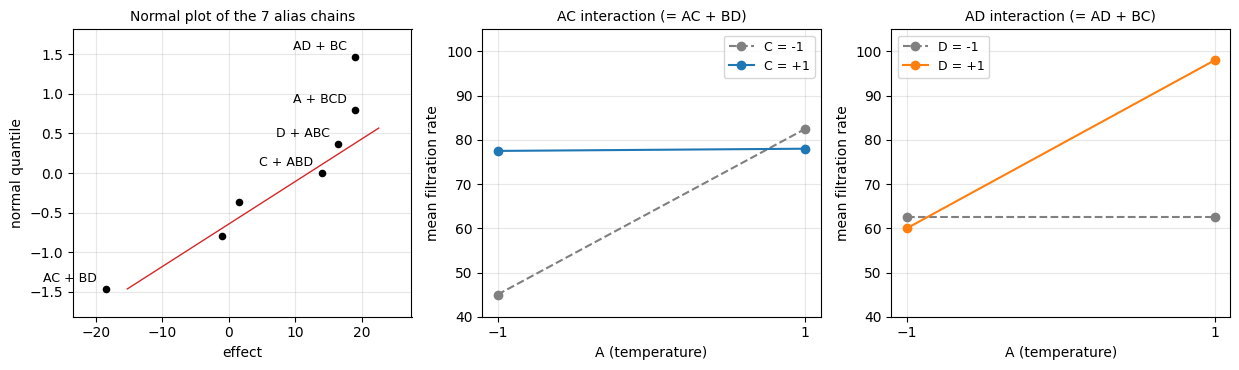

In [8]:
# Figure of Lecture 8: normal plot of the alias chains and the AC and AD interaction plots
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.8))
effect_plot(e81, n_label=5, ax=ax[0], title="Normal plot of the 7 alias chains")
for k_, (w, col, al) in enumerate([("C", "tab:blue", "BD"), ("D", "tab:orange", "BC")]):
    for lev, ls in [(-1, "--"), (1, "-")]:
        mm = d[d[w] == lev].groupby("A")["y"].mean()
        ax[1 + k_].plot(mm.index, mm.values, ls, marker="o", color=col if lev > 0 else "grey", label=f"{w} = {lev:+d}")
    ax[1 + k_].set_xticks([-1, 1]); ax[1 + k_].set_xlabel("A (temperature)"); ax[1 + k_].set_ylim(40, 105)
    ax[1 + k_].set_ylabel("mean filtration rate"); ax[1 + k_].grid(alpha=0.3); ax[1 + k_].legend(fontsize=9)
    ax[1 + k_].set_title(f"A{w} interaction (= A{w} + {al})", fontsize=10)
plt.tight_layout(); plt.show()

$[A]$, $[C]$, $[D]$, $[AC] = AC + BD$ and $[AD] = AD + BC$ are large, $[B]$ and $[AB]$ are small. Since $B$ is inactive,
the **heredity** principle suggests that the large chains are $AC$ and $AD$. Dropping $B$ projects the design into a single
replicate of a $2^3$ design in $A$, $C$, $D$; the two remaining degrees of freedom ($[B]$ and $[AB] = AB + CD$) are used as
error.

In [9]:
m81 = smf.ols("y ~ A*C + A*D", data=d).fit()
print(m81.summary().tables[1])
print(f"s = {np.sqrt(m81.scale):.3f} on {m81.df_resid:.0f} df, R2 = {m81.rsquared:.4f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     70.7500      0.637    111.002      0.000      68.008      73.492
A              9.5000      0.637     14.905      0.004       6.758      12.242
C              7.0000      0.637     10.983      0.008       4.258       9.742
A:C           -9.2500      0.637    -14.513      0.005     -11.992      -6.508
D              8.2500      0.637     12.944      0.006       5.508      10.992
A:D            9.5000      0.637     14.905      0.004       6.758      12.242
s = 1.803 on 2 df, R2 = 0.9979


In [10]:
# comparison with the same model fitted to all 16 runs of the full 2^4 design (Exercise 6)
mfull = smf.ols("Rate ~ A*C + A*D", data=full).fit()
pd.DataFrame({"half fraction (8 runs)": m81.params, "full 2^4 (16 runs)": mfull.params}).round(4)

,half fraction (8 runs),full 2^4 (16 runs)
Intercept,70.75,70.0625
A,9.50,10.8125
C,7.00,4.9375
A:C,-9.25,-9.0625
D,8.25,7.3125
A:D,9.50,8.3125


### Confirmation run

High filtration rate with a low concentration of formaldehyde: $A = +$, $C = -$, $D = +$. The run with $B = -$ ($ad$) is in
the fraction, the run with $B = +$ ($abd$) is not, so it is a reasonable confirmation run. Predict it with a 95% prediction
interval and compare with the observed value (in the full experiment it was run: 104).

In [11]:
new = pd.DataFrame({"A": [1], "B": [1], "C": [-1], "D": [1]})
pr = m81.get_prediction(new).summary_frame(alpha=0.05)
display(pr[["mean", "obs_ci_lower", "obs_ci_upper"]].round(2))
observed = full.query("A == 1 and B == 1 and C == -1 and D == 1")["Rate"].item()
print("observed:", observed)

,mean,obs_ci_lower,obs_ci_upper
0,100.25,89.99,110.51


observed: 104


The observation lies inside the prediction interval: a successful confirmation run. (With only 2 residual degrees of freedom
the interval is wide; a confirmation run with more data would be stronger.)

## 3. Lecture example: adding the alternate fraction (Example 8.3)

Is the large chain $AC + BD$ really $AC$? Run the alternate fraction $I = -ABCD$ (the other 8 runs of the $2^4$ design).
From the principal fraction $\ell_i \to i + \text{alias}$, from the alternate one $\ell'_i \to i - \text{alias}$, hence
$\frac12(\ell_i + \ell'_i) \to i$ and $\frac12(\ell_i - \ell'_i) \to \text{alias}$.

In [12]:
alt = fractional_design("ABC", {"D": "-ABC"}).merge(full, on=["A", "B", "C", "D"]).rename(columns={"Rate": "y"})
rows = []
for w in ["A", "B", "C", "D", "AB", "AC", "AD"]:
    l1, l2 = effect(d, w), effect(alt, w)
    rows.append([w, aliases(w, ["ABCD"])[0], l1, l2, (l1 + l2) / 2, (l1 - l2) / 2])
tab = pd.DataFrame(rows, columns=["effect", "alias", "l", "l'", "(l+l')/2", "(l-l')/2"])
tab.round(2)

,effect,alias,l,l',(l+l')/2,(l-l')/2
0,A,BCD,19.0,24.25,21.62,-2.62
1,B,ACD,1.5,4.75,3.12,-1.62
2,C,ABD,14.0,5.75,9.88,4.12
3,D,ABC,16.5,12.75,14.62,1.88
4,AB,CD,-1.0,1.25,0.12,-1.12
5,AC,BD,-18.5,-17.75,-18.12,-0.38
6,AD,BC,19.0,14.25,16.62,2.38


In [13]:
# check: the combined estimates are the effects of the full 2^4 design
pd.Series({w: effect(full, w, "Rate") for w in list(tab.effect) + list(tab.alias)}).round(2)

A      21.62
B       3.12
C       9.88
D      14.62
AB      0.12
AC    -18.12
AD     16.62
BCD    -2.62
ACD    -1.62
ABD     4.12
ABC     1.88
CD     -1.12
BD     -0.38
BC      2.38
dtype: float64

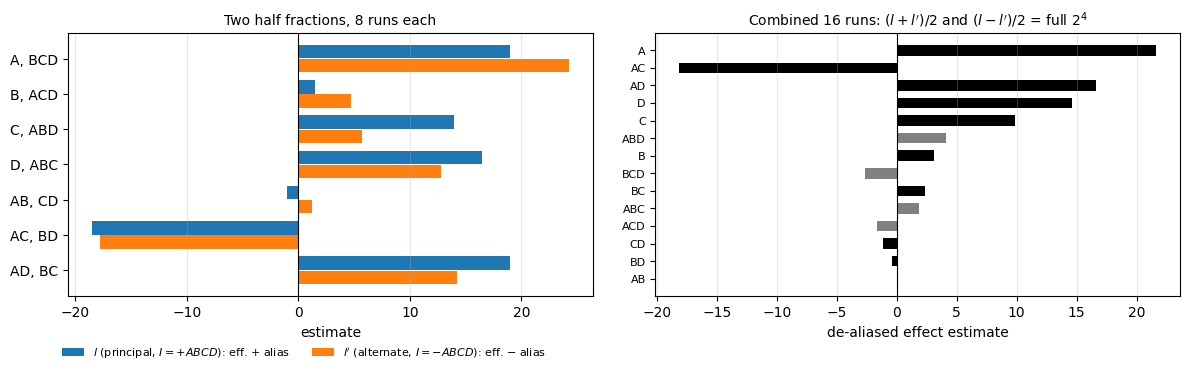

In [14]:
# Figure of Lecture 8: estimates from the two fractions and the de-aliased effects
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
yy = np.arange(len(tab))[::-1]
ax[0].barh(yy + 0.2, tab["l"], height=0.38, color="tab:blue", label=r"$l$ (principal, $I=+ABCD$): eff. + alias")
ax[0].barh(yy - 0.2, tab["l'"], height=0.38, color="tab:orange", label=r"$l'$ (alternate, $I=-ABCD$): eff. $-$ alias")
ax[0].set_yticks(yy); ax[0].set_yticklabels([f"{a}, {b}" for a, b in zip(tab.effect, tab.alias)])
ax[0].axvline(0, color="k", lw=0.8); ax[0].grid(axis="x", alpha=0.3); ax[0].set_xlabel("estimate")
ax[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.15), ncol=2, frameon=False)
ax[0].set_title("Two half fractions, 8 runs each", fontsize=10)
comb = pd.concat([pd.Series(tab["(l+l')/2"].to_numpy(), index=tab.effect),
                  pd.Series(tab["(l-l')/2"].to_numpy(), index=tab.alias)])
comb = comb.reindex(comb.abs().sort_values().index)
ax[1].barh(np.arange(len(comb)), comb, color=["k" if len(n) <= 2 else "grey" for n in comb.index], height=0.6)
ax[1].set_yticks(np.arange(len(comb))); ax[1].set_yticklabels(comb.index, fontsize=8)
ax[1].axvline(0, color="k", lw=0.8); ax[1].grid(axis="x", alpha=0.3); ax[1].set_xlabel("de-aliased effect estimate")
ax[1].set_title(r"Combined 16 runs: $(l+l')/2$ and $(l-l')/2$ = full $2^4$", fontsize=10)
plt.tight_layout(); plt.show()

$AC$ and $AD$ are large, $BD$ and $BC$ are small: the heredity assumption was correct. The two fractions are two blocks of
the $2^4$ design with $ABCD$ confounded with blocks (Exercise 7): if conditions changed between the two stages, the
difference ends up in $ABCD$.

## 4. The alias matrix

If we fit $y = X_1\beta_1 + \varepsilon$ but the true model is $y = X_1\beta_1 + X_2\beta_2 + \varepsilon$, then
$E(\hat\beta_1) = \beta_1 + A\beta_2$ with $A = (X_1^TX_1)^{-1}X_1^TX_2$. Rows of $A$ correspond to the fitted effects,
columns to the omitted ones. For regular fractions the entries are 0 or $\pm1$; for nonregular designs (Plackett-Burman,
Lecture 9) they can be fractions such as $\pm 1/3$.

In [15]:
def model_matrix(df, terms):
    """Columns of products of factor columns, e.g. terms ["A", "AB"]; "I" is the intercept."""
    return np.column_stack([np.ones(len(df)) if t == "I" else df[list(t)].prod(axis=1) for t in terms])


d3 = fractional_design("AB", {"C": "AB"})                         # 2^(3-1)_III, I = ABC
t1, t2 = ["I", "A", "B", "C"], ["AB", "AC", "BC"]
pd.DataFrame(alias_matrix(model_matrix(d3, t1), model_matrix(d3, t2)), index=t1, columns=t2)

,AB,AC,BC
I,0.0,0.0,0.0
A,0.0,0.0,1.0
B,0.0,1.0,0.0
C,1.0,0.0,0.0


In [16]:
# 2^(7-4)_III: each main effect is aliased with three two-factor interactions
d74 = fractional_design("ABC", {"D": "AB", "E": "AC", "F": "BC", "G": "ABC"})
t1 = list("ABCDEFG")
t2 = ["".join(c) for c in itertools.combinations("ABCDEFG", 2)]
A74 = pd.DataFrame(alias_matrix(model_matrix(d74, t1), model_matrix(d74, t2)), index=t1, columns=t2)
A74.loc[:, (A74 != 0).any()].astype(int)

,AB,AC,AD,AE,AF,AG,BC,BD,BE,BF,...,CD,CE,CF,CG,DE,DF,DG,EF,EG,FG
A,0,0,0,0,0,0,0,1,0,0,...,0,1,0,0,0,0,0,0,0,1
B,0,0,1,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
C,0,0,0,1,0,0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0
D,1,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0
E,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
F,0,0,0,0,0,1,1,0,0,0,...,0,0,0,0,1,0,0,0,0,0
G,0,0,0,0,1,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0


## 5. Lecture example: a $2^{5-1}_V$ design for process improvement (Example 8.2)

Integrated circuit manufacturing, response yield (%). Factors: aperture setting ($A$), exposure time ($B$), develop time
($C$), mask dimension ($D$), etch time ($E$). Generator $E = ABCD$, $I = ABCDE$, resolution V.

In [17]:
d2 = fractional_design("ABCD", {"E": "ABCD"})
d2["y"] = [8, 9, 34, 52, 16, 22, 45, 60, 6, 10, 30, 50, 15, 21, 44, 63]
names = ["".join(c) for r in (1, 2) for c in itertools.combinations("ABCDE", r)]
eff2 = pd.Series({w: effect(d2, w) for w in names})
eff2.sort_values(key=abs, ascending=False).round(3)

B     33.875
A     11.125
C     10.875
AB     6.875
DE    -1.375
AD     1.125
AE     1.125
D     -0.875
CD     0.875
BC     0.625
E      0.625
AC     0.375
CE     0.375
BD    -0.125
BE    -0.125
dtype: float64

In [18]:
m82 = smf.ols("y ~ A*B + C", data=d2).fit()
display(anova_lm(m82))
print(m82.params.round(4))

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,495.0625,495.0625,193.195122,2.534760e-08
B,1.0,4590.0625,4590.0625,1791.243902,1.560258e-13
A:B,1.0,189.0625,189.0625,73.780488,3.301648e-06
C,1.0,473.0625,473.0625,184.609756,3.213624e-08
Residual,11.0,28.1875,2.5625,NaN,NaN


Intercept    30.3125
A             5.5625
B            16.9375
A:B           3.4375
C             5.4375
dtype: float64


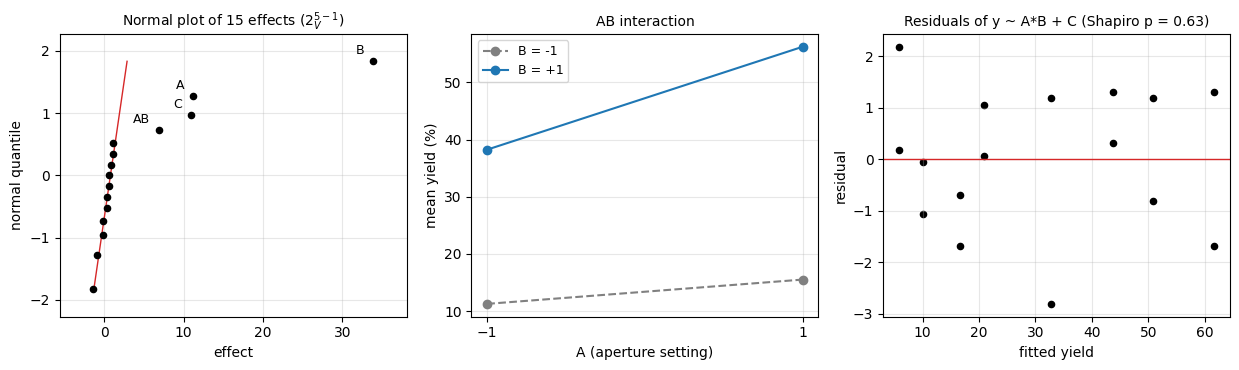

In [19]:
# Figure of Lecture 8: normal plot of the effects, AB interaction, residuals
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.8))
effect_plot(eff2, n_label=4, ax=ax[0], title="Normal plot of 15 effects ($2^{5-1}_V$)")
for lev, col in [(-1, "grey"), (1, "tab:blue")]:
    mm = d2[d2.B == lev].groupby("A")["y"].mean()
    ax[1].plot(mm.index, mm.values, "-" if lev > 0 else "--", marker="o", color=col, label=f"B = {lev:+d}")
ax[1].set_xticks([-1, 1]); ax[1].set_xlabel("A (aperture setting)"); ax[1].set_ylabel("mean yield (%)")
ax[1].set_title("AB interaction", fontsize=10); ax[1].legend(fontsize=9); ax[1].grid(alpha=0.3)
ax[2].scatter(m82.fittedvalues, m82.resid, color="k", s=20); ax[2].axhline(0, color="tab:red", lw=1)
ax[2].set_xlabel("fitted yield"); ax[2].set_ylabel("residual"); ax[2].grid(alpha=0.3)
ax[2].set_title(f"Residuals of y ~ A*B + C (Shapiro p = {stats.shapiro(m82.resid).pvalue:.2f})", fontsize=10)
plt.tight_layout(); plt.show()

$D$ and $E$ are inactive, so the $2^{5-1}$ design collapses into **two replicates of a $2^3$ design** in $A$, $B$, $C$ (check
below: every combination of $A$, $B$, $C$ appears twice). The 11 residual degrees of freedom contain the pure error of the
replicates.

In [20]:
d2.groupby(["A", "B", "C"])["y"].agg(list)

A   B   C 
-1  -1  -1      [8, 6]
         1    [16, 15]
     1  -1    [34, 30]
         1    [45, 44]
 1  -1  -1     [9, 10]
         1    [22, 21]
     1  -1    [52, 50]
         1    [60, 63]
Name: y, dtype: object

## 6. Lecture example: injection molding, a $2^{6-2}_{IV}$ design (Example 8.4)

Excessive shrinkage of parts. Factors: mold temperature ($A$), screw speed ($B$), holding time ($C$), cycle time ($D$), gate
size ($E$), holding pressure ($F$). Generators $E = ABC$, $F = BCD$; $I = ABCE = BCDF = ADEF$.

In [21]:
d4 = fractional_design("ABCD", {"E": "ABC", "F": "BCD"})
d4["y"] = [6, 10, 32, 60, 4, 15, 26, 60, 8, 12, 34, 60, 16, 5, 37, 52]     # shrinkage (x 10)
d4

,run,A,B,C,D,E,F,y
0,(1),-1,-1,-1,-1,-1,-1,6
1,ae,1,-1,-1,-1,1,-1,10
2,bef,-1,1,-1,-1,1,1,32
3,abf,1,1,-1,-1,-1,1,60
4,cef,-1,-1,1,-1,1,1,4
5,acf,1,-1,1,-1,-1,1,15
6,bc,-1,1,1,-1,-1,-1,26
7,abce,1,1,1,-1,1,-1,60
8,df,-1,-1,-1,1,-1,1,8
9,adef,1,-1,-1,1,1,1,12


In [22]:
# the 15 alias chains (main effects, two-factor interactions and the two chains of three-factor interactions)
words62 = defining_relation(["ABCE", "BCDF"])
seen, cols = set(), {}
for r in (1, 2, 3):
    for c in itertools.combinations("ABCDEF", r):
        w = "".join(c)
        chain = frozenset([w] + aliases(w, words62))
        if chain in seen or len(seen) == 15:
            continue
        seen.add(chain)
        label = "=".join(sorted([a for a in chain if len(a) <= 2] or [w], key=lambda s: (len(s), s)))
        cols[label] = d4[list(w)].prod(axis=1)
e84 = pd.Series({k: (v * d4.y).sum() / 8 for k, v in cols.items()})
e84.sort_values(key=abs, ascending=False).round(3)

B           35.625
A           13.875
AB=CE       11.875
AD=EF       -5.375
ABF         -4.875
AE=BC=DF    -1.875
AC=BE       -1.625
D            1.375
C           -0.875
AF=DE        0.625
E            0.375
F            0.375
BD=CF       -0.125
BF=CD       -0.125
ABD          0.125
dtype: float64

In [23]:
m84 = smf.ols("y ~ A*B", data=d4).fit()
display(anova_lm(m84))
print(m84.params.round(4))

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,770.0625,770.062500,37.148744,5.377022e-05
B,1.0,5076.5625,5076.562500,244.899497,2.391656e-09
A:B,1.0,564.0625,564.062500,27.211055,2.159842e-04
Residual,12.0,248.7500,20.729167,NaN,NaN


Intercept    27.3125
A             6.9375
B            17.8125
A:B           5.9375
dtype: float64


**Dispersion effects** (Exercise 6): with the location model $A$, $B$, $AB$ removed, compare the spread of the residuals at the
two levels of each column, $F^*_i = \ln\big(S^2(i+)/S^2(i-)\big)$.

In [24]:
d4["res"] = m84.resid
disp = pd.Series({k: np.log(d4.res[v > 0].var() / d4.res[v < 0].var()) for k, v in cols.items()})
print(d4.groupby("C")["res"].std().round(2))
disp.sort_values().round(2)

C
-1    1.63
 1    5.70
Name: res, dtype: float64


AC=BE      -0.41
A          -0.38
F          -0.30
AE=BC=DF   -0.24
BD=CF      -0.19
B          -0.19
E          -0.04
AB=CE       0.11
ABF         0.23
AD=EF       0.42
D           0.51
BF=CD       0.51
ABD         0.52
AF=DE       0.72
C           2.50
dtype: float64

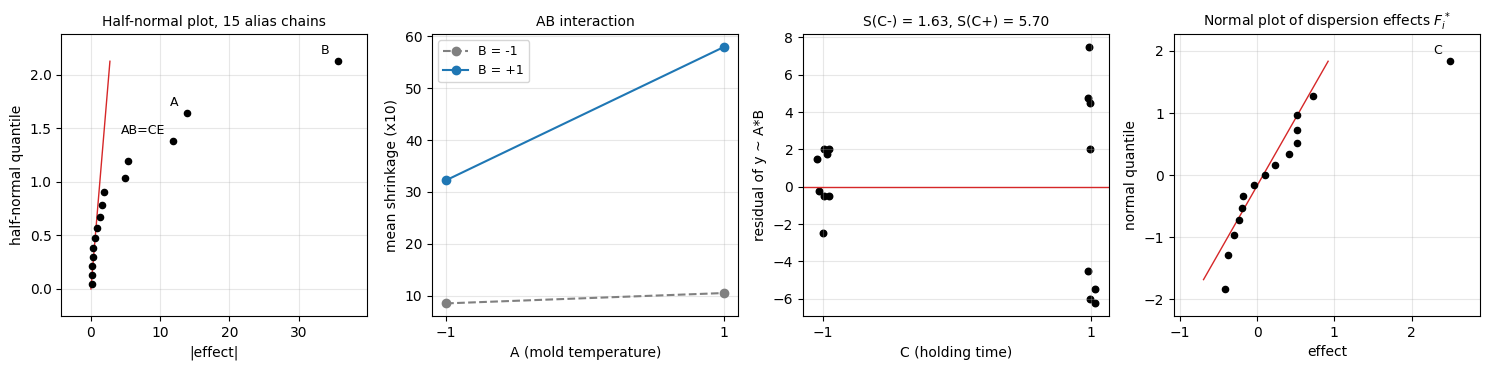

In [25]:
# Figure of Lecture 8: half-normal plot, AB interaction, residuals vs C, dispersion effects
rng = np.random.default_rng(1)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
effect_plot(e84, half=True, n_label=3, ax=ax[0], title="Half-normal plot, 15 alias chains")
for lev, col in [(-1, "grey"), (1, "tab:blue")]:
    mm = d4[d4.B == lev].groupby("A")["y"].mean()
    ax[1].plot(mm.index, mm.values, "-" if lev > 0 else "--", marker="o", color=col, label=f"B = {lev:+d}")
ax[1].set_xticks([-1, 1]); ax[1].set_xlabel("A (mold temperature)"); ax[1].set_ylabel("mean shrinkage (x10)")
ax[1].set_title("AB interaction", fontsize=10); ax[1].legend(fontsize=9); ax[1].grid(alpha=0.3)
ax[2].scatter(d4.C + rng.uniform(-0.05, 0.05, 16), d4.res, color="k", s=22); ax[2].axhline(0, color="tab:red", lw=1)
s = d4.groupby("C")["res"].std()
ax[2].set_xticks([-1, 1]); ax[2].set_xlabel("C (holding time)"); ax[2].set_ylabel("residual of y ~ A*B")
ax[2].set_title(f"S(C-) = {s[-1]:.2f}, S(C+) = {s[1]:.2f}", fontsize=10); ax[2].grid(alpha=0.3)
effect_plot(disp, n_label=1, ax=ax[3], title=r"Normal plot of dispersion effects $F^*_i$")
plt.tight_layout(); plt.show()

Low screw speed ($B-$) gives a low mean shrinkage regardless of $A$; low holding time ($C-$) gives a much smaller
part-to-part variability ($F^*_C = 2.50$). Recommendation: $A-$, $B-$, $C-$.

## 7. Choosing a $2^{k-p}$ design: minimum aberration; blocking a fraction

Among designs of the same resolution prefer the one with the fewest shortest words (**minimum aberration**). Compare the
word length patterns $(A_3, A_4, \dots)$ from the left.

In [26]:
for g in (["ABCF", "BCDG"], ["ABCF", "ADEG"], ["ABCDF", "ABDEG"]):
    print(f"{str(g):22s} I = {' = '.join(defining_relation(g)):24s} WLP = {wlp(g, 7)}")

['ABCF', 'BCDG']       I = ABCF = ADFG = BCDG       WLP = [0, 3, 0, 0, 0]
['ABCF', 'ADEG']       I = ABCF = ADEG = BCDEFG     WLP = [0, 2, 0, 1, 0]
['ABCDF', 'ABDEG']     I = CEFG = ABCDF = ABDEG     WLP = [0, 1, 2, 0, 0]


In [27]:
# how many two-factor interactions are clear (not aliased with main effects or other 2fi)?
for g in (["ABCF", "BCDG"], ["ABCF", "ADEG"], ["ABCDF", "ABDEG"]):
    words = defining_relation(g)
    twofi = ["".join(c) for c in itertools.combinations("ABCDEFG", 2)]
    clear = [t for t in twofi if all(len(a) > 2 for a in aliases(t, words))]
    print(g, len(clear), "clear two-factor interactions")

['ABCF', 'BCDG'] 6 clear two-factor interactions
['ABCF', 'ADEG'] 9 clear two-factor interactions
['ABCDF', 'ABDEG'] 15 clear two-factor interactions


**Blocking a fraction:** choose an effect to confound with blocks; all its aliases are confounded too. The $2^{6-2}_{IV}$
design in two blocks with $ABD$ (a chain of three-factor interactions only):

In [28]:
d6 = fractional_design("ABCD", {"E": "ABC", "F": "BCD"})
d6["Block"] = np.where(d6.A * d6.B * d6.D < 0, 1, 2)
print(d6.groupby("Block")["run"].apply(", ".join).to_string())
print("confounded with blocks: ABD =", " = ".join(aliases("ABD", defining_relation(["ABCE", "BCDF"]))))

Block
1    (1), abf, cef, abce, adef, bde, acd, bcdf
2       ae, bef, acf, bc, df, abd, cde, abcdef
confounded with blocks: ABD = CDE = BEF = ACF


## 8. Resolution III designs and the fold-over (Example 8.7)

**Eye focus time** (ms): acuity ($A$), distance from target to eye ($B$), target shape ($C$), illumination level ($D$), target
size ($E$), target density ($F$), subject ($G$). A saturated $2^{7-4}_{III}$ design with $D = AB$, $E = AC$, $F = BC$,
$G = ABC$.

In [29]:
e = fractional_design("ABC", {"D": "AB", "E": "AC", "F": "BC", "G": "ABC"})
e["y"] = [85.5, 75.1, 93.2, 145.4, 83.7, 77.6, 95.0, 141.8]
gens74 = ["ABD", "ACE", "BCF", "ABCG"]
for ch in alias_chains("ABCDEFG", gens74)[:7]:
    print(ch)
l1 = pd.Series({f: effect(e, f) for f in "ABCDEFG"})
l1.round(2)

A = BD = CE = FG
B = AD = CF = EG
C = AE = BF = DG
D = AB = CG = EF
E = AC = BG = DF
F = AG = BC = DE
G = AF = BE = CD


A    20.62
B    38.38
C    -0.28
D    28.88
E    -0.27
F    -0.63
G    -2.42
dtype: float64

$[A]$, $[B]$ and $[D]$ are large. Main effects $A$, $B$, $D$? Or $A$, $B$, $AB$ ($AB$ is in $[D]$)? Or $B$, $D$, $BD$? Because
$ABD$ is a word of the defining relation, the design projects into two replicates of a $2^{3-1}_{III}$ design in $A$, $B$,
$D$:

In [30]:
print(e.groupby(["A", "B", "D"]).size())        # only 4 of the 8 combinations, each twice
print(e.groupby(["A", "B", "C"]).size())        # a full 2^3: assigning illumination to C would have been better

A   B   D 
-1  -1   1    2
     1  -1    2
 1  -1  -1    2
     1   1    2
dtype: int64
A   B   C 
-1  -1  -1    1
         1    1
     1  -1    1
         1    1
 1  -1  -1    1
         1    1
     1  -1    1
         1    1
dtype: int64


**Full fold-over:** a second fraction with the signs of **all** factors reversed. Then $\frac12(\ell_i + \ell'_i)$ estimates the
main effect $i$ and $\frac12(\ell_i - \ell'_i)$ its chain of two-factor interactions. The combined design has resolution at least IV.

In [31]:
fold = -e[list("ABCDEFG")]                      # new runs: all signs reversed
fold.insert(0, "run", fold.apply(lambda r: "".join(c.lower() for c in "ABCDEFG" if r[c] > 0) or "(1)", axis=1))
fold["y"] = [91.3, 136.7, 82.4, 73.4, 94.1, 143.8, 87.3, 71.9]
l2 = pd.Series({f: effect(fold, f) for f in "ABCDEFG"})
chains = [ch.split(" = ", 1)[1] for ch in alias_chains("ABCDEFG", gens74)[:7]]
pd.DataFrame({"l": l1, "l'": l2, "main (l+l')/2": (l1 + l2) / 2, "2fi (l-l')/2": (l1 - l2) / 2,
              "2fi chain": chains}).round(2)

,l,l',main (l+l')/2,2fi (l-l')/2,2fi chain
A,20.62,-17.68,1.47,19.15,BD = CE = FG
B,38.38,37.72,38.05,0.33,AD = CF = EG
C,-0.28,-3.33,-1.80,1.52,AE = BF = DG
D,28.88,29.88,29.38,-0.50,AB = CG = EF
E,-0.27,0.52,0.12,-0.40,AC = BG = DF
F,-0.63,1.63,0.50,-1.13,AG = BC = DE
G,-2.42,2.68,0.13,-2.55,AF = BE = CD


In [32]:
# defining relation of the combined 16-run design: the words of even length (they keep their sign)
both = pd.concat([e, fold], ignore_index=True)
words_both = [w for w in defining_relation(gens74) if np.all(both[list(w)].prod(axis=1) == 1)]
print("I =", " = ".join(words_both), " -> resolution", min(map(len, words_both)))

I = ABCG = ABEF = ACDF = ADEG = BCDE = BDFG = CEFG  -> resolution 4


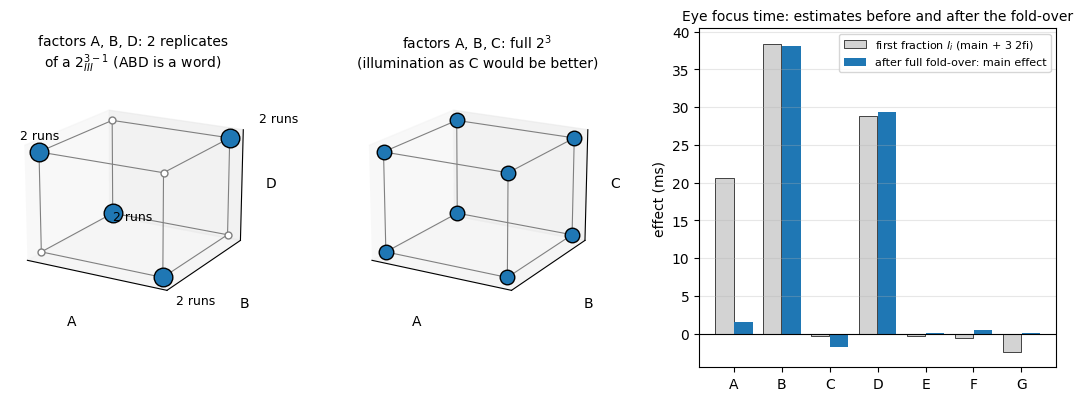

In [33]:
# Figure of Lecture 8: projection into A, B, D vs A, B, C and the estimates before and after the fold-over
fig = plt.figure(figsize=(13.5, 4.4))
gs = fig.add_gridspec(1, 3, width_ratios=[1.1, 1.1, 1.6], wspace=0.35)
for j, (f3, ttl) in enumerate([("D", "factors A, B, D: 2 replicates\nof a $2^{3-1}_{III}$ (ABD is a word)"),
                               ("C", "factors A, B, C: full $2^3$\n(illumination as C would be better)")]):
    a3 = fig.add_subplot(gs[j], projection="3d")
    cube_edges(a3)
    cnt = e.groupby(["A", "B", f3]).size()
    for x in itertools.product([-1, 1], repeat=3):
        n = cnt.get(x, 0)
        a3.scatter(*x, s=40 + 70 * n if n else 25, color="tab:blue" if n else "white",
                   edgecolor="k" if n else "grey", depthshade=False)
        if n > 1:
            a3.text(x[0] * 1.25 + 0.1, x[1] * 1.25, x[2] * 1.3, f"{n} runs", fontsize=9)
    a3.set_xlabel("A"); a3.set_ylabel("B"); a3.set_zlabel(f3, labelpad=-8)
    a3.set_xticks([]); a3.set_yticks([]); a3.set_zticks([]); a3.view_init(elev=18, azim=-60)
    a3.set_title(ttl, fontsize=10)
ax = fig.add_subplot(gs[2])
xx = np.arange(7)
ax.bar(xx - 0.2, l1, width=0.38, color="lightgrey", edgecolor="k", lw=0.5, label="first fraction $l_i$ (main + 3 2fi)")
ax.bar(xx + 0.2, (l1 + l2) / 2, width=0.38, color="tab:blue", label="after full fold-over: main effect")
ax.set_xticks(xx); ax.set_xticklabels(list("ABCDEFG")); ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("effect (ms)"); ax.grid(axis="y", alpha=0.3); ax.legend(fontsize=8, loc="upper right")
ax.set_title("Eye focus time: estimates before and after the fold-over", fontsize=10)
plt.show()

The large $[A] = 20.63$ was the interaction chain $BD + CE + FG = 19.15$; the main effect of acuity is negligible. Active
effects: distance $B$, illumination $D$ and, by heredity, their interaction $BD$.

**Single-factor fold-over:** reverse the signs of one factor only, e.g. $D$. The combined design estimates $D$ and all
two-factor interactions with $D$ clear of the other main effects and two-factor interactions. We check it with the alias
matrix of the combined 16 runs (main effects and the 2fi containing $D$ fitted, the other 2fi omitted):

In [34]:
foldD = e[list("ABCDEFG")].copy()               # design only: the responses of these new runs are not known
foldD["D"] = -foldD["D"]
combD = pd.concat([e[list("ABCDEFG")], foldD], ignore_index=True)
t1 = ["I"] + list("ABCDEFG") + ["AD", "BD", "CD", "DE", "DF", "DG"]
t2 = [t for t in ("".join(c) for c in itertools.combinations("ABCDEFG", 2)) if "D" not in t]
AD = pd.DataFrame(alias_matrix(model_matrix(combD, t1), model_matrix(combD, t2)), index=t1, columns=t2)
AD.loc[["D", "AD", "BD", "CD", "DE", "DF", "DG"]].abs().max(axis=1)      # 0: clear of the other 2fi

D     0.0
AD    0.0
BD    0.0
CD    0.0
DE    0.0
DF    0.0
DG    0.0
dtype: float64

## Assignment

Work on the assignment in class (in pairs, if you like). Whatever you do not finish in class, finish at home as homework.

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **8.3, 8.9, 8.11, 8.23,
  8.24 and 8.27**. The data of every problem are loaded or entered in the cell below its description.
* For every design write down the generators, the complete defining relation, the resolution and the alias chains you need.
  For every test state the hypotheses, the test statistic, its $p$-value and your decision; end each problem with a
  conclusion in one or two sentences.
* The code is only half of the work. Explain every result in your own words: which effects you believe are active and why
  (sparsity, hierarchy, heredity), what the aliasing allows you to conclude and what it does not, and which runs you would
  add next. Be ready to present and defend your solution of any problem at the beginning of the next exercise.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex08_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 29 November 2026.**

### Problem 8.3: plasma etch experiment

Example 6.1 (Exercise 5): etch rate (Å/min) of silicon nitride; factors gap ($A$), C$_2$F$_6$ gas flow ($B$) and RF power ($C$);
two replicates of the $2^3$ design. Data: `plasma.txt` (columns `R1`, `R2` = replicates).

In [35]:
p83 = pd.read_csv(URL + "plasma.txt", sep=r"\s+")
p83

,Run,A,B,C,R1,R2
0,1,-1,-1,-1,550,604
1,2,1,-1,-1,669,650
2,3,-1,1,-1,633,601
3,4,1,1,-1,642,635
4,5,-1,-1,1,1037,1052
5,6,1,-1,1,749,868
6,7,-1,1,1,1075,1063
7,8,1,1,1,729,860


Suppose that only a one-half fraction of the design could be run. Set up the design and analyze the data (use both replicates
of the runs in the fraction). What can and what cannot be estimated? Compare your conclusions with the analysis of the full
$2^3$ design in Exercise 5. Would the alternate fraction lead to the same conclusions?

**Solution:**

### Problem 8.9: color of a chemical product

R. D. Snee (1985) describes a $2^{5-1}$ design with $I = ABCDE$ used to investigate the effects of five factors on the color of
a chemical product: $A$ = solvent/reactant, $B$ = catalyst/reactant, $C$ = temperature, $D$ = reactant purity, $E$ = reactant pH.
Data: the responses (color) of the 16 treatment combinations, entered in the cell below.

In [36]:
p89 = design_from_runs(["e", "a", "b", "abe", "c", "ace", "bce", "abc",
                        "d", "ade", "bde", "abd", "cde", "acd", "bcd", "abcde"], "ABCDE")
p89["y"] = [-0.63, 2.51, -2.68, 1.66, 2.06, 1.22, -2.09, 1.93,
            6.79, 5.47, 3.45, 5.68, 5.22, 4.38, 4.30, 4.05]
p89

,run,A,B,C,D,E,y
0,e,-1,-1,-1,-1,1,-0.63
1,a,1,-1,-1,-1,-1,2.51
2,b,-1,1,-1,-1,-1,-2.68
3,abe,1,1,-1,-1,1,1.66
4,c,-1,-1,1,-1,-1,2.06
5,ace,1,-1,1,-1,1,1.22
6,bce,-1,1,1,-1,1,-2.09
7,abc,1,1,1,-1,-1,1.93
8,d,-1,-1,-1,1,-1,6.79
9,ade,1,-1,-1,1,1,5.47


(a) Prepare a normal probability plot of the effects. Which effects seem active?

(b) Calculate the residuals. Construct a normal probability plot of the residuals and plot the residuals versus the fitted
values. Comment on the plots.

(c) If any factors are negligible, collapse the $2^{5-1}$ design into a full factorial in the active factors. Comment on the
resulting design, and interpret the results.

**Solution:**

### Problem 8.11: a $2^{5-2}$ design for yield

An article in *Industrial and Engineering Chemistry* (1970) uses a $2^{5-2}$ design to investigate the effect of $A$ =
condensation temperature, $B$ = amount of material 1, $C$ = solvent volume, $D$ = condensation time and $E$ = amount of
material 2 on yield. Data: the yields of the 8 treatment combinations, entered in the cell below.

In [37]:
p811 = design_from_runs(["e", "ab", "ad", "bc", "cd", "ace", "bde", "abcde"], "ABCDE")
p811["y"] = [23.2, 15.5, 16.9, 16.2, 23.8, 23.4, 16.8, 18.1]
p811

,run,A,B,C,D,E,y
0,e,-1,-1,-1,-1,1,23.2
1,ab,1,1,-1,-1,-1,15.5
2,ad,1,-1,-1,1,-1,16.9
3,bc,-1,1,1,-1,-1,16.2
4,cd,-1,-1,1,1,-1,23.8
5,ace,1,-1,1,-1,1,23.4
6,bde,-1,1,-1,1,1,16.8
7,abcde,1,1,1,1,1,18.1


(a) Verify that the design generators used were $I = ACE$ and $I = BDE$.

(b) Write down the complete defining relation and the aliases for this design.

(c) Estimate the main effects.

(d) Prepare an analysis of variance table. Verify that the $AB$ and $AD$ interactions are available to use as error.

(e) Plot the residuals versus the fitted values. Also construct a normal probability plot of the residuals. Comment on the
results.

**Solution:**

### Problem 8.23: fold-over in a simulation experiment

An industrial engineer is conducting an experiment using a Monte Carlo simulation model of an inventory system. The
independent variables are the order quantity ($A$), the reorder point ($B$), the setup cost ($C$), the backorder cost ($D$) and
the carrying cost rate ($E$); the response is the average annual cost. She uses a $2^{5-2}_{III}$ design with $I = ABD$ and
$I = BCE$. Data: the original fraction and the two possible second fractions of parts (b) and (c), entered in the cell below.

In [38]:
p823 = design_from_runs(["de", "ae", "b", "abd", "cd", "ac", "bce", "abcde"], "ABCDE")
p823["y"] = [95, 134, 158, 190, 92, 187, 155, 185]                  # original fraction
p823b = design_from_runs(["ade", "e", "ab", "bd", "acd", "c", "abce", "bcde"], "ABCDE")
p823b["y"] = [136, 93, 187, 153, 139, 99, 191, 150]                 # second fraction, part (b)
p823c = design_from_runs(["abc", "ce", "bcd", "acde", "abe", "bde", "ad", "(1)"], "ABCDE")
p823c["y"] = [189, 96, 154, 135, 193, 152, 137, 98]                 # second fraction, part (c)
display(p823, p823b, p823c)

,run,A,B,C,D,E,y
0,de,-1,-1,-1,1,1,95
1,ae,1,-1,-1,-1,1,134
2,b,-1,1,-1,-1,-1,158
3,abd,1,1,-1,1,-1,190
4,cd,-1,-1,1,1,-1,92
5,ac,1,-1,1,-1,-1,187
6,bce,-1,1,1,-1,1,155
7,abcde,1,1,1,1,1,185


,run,A,B,C,D,E,y
0,ade,1,-1,-1,1,1,136
1,e,-1,-1,-1,-1,1,93
2,ab,1,1,-1,-1,-1,187
3,bd,-1,1,-1,1,-1,153
4,acd,1,-1,1,1,-1,139
5,c,-1,-1,1,-1,-1,99
6,abce,1,1,1,-1,1,191
7,bcde,-1,1,1,1,1,150


,run,A,B,C,D,E,y
0,abc,1,1,1,-1,-1,189
1,ce,-1,-1,1,-1,1,96
2,bcd,-1,1,1,1,-1,154
3,acde,1,-1,1,1,1,135
4,abe,1,1,-1,-1,1,193
5,bde,-1,1,-1,1,1,152
6,ad,1,-1,-1,1,-1,137
7,(1),-1,-1,-1,-1,-1,98


(a) Verify that the treatment combinations of the original fraction are correct. Estimate the effects, assuming three-factor
and higher interactions are negligible.

(b) Suppose that the second fraction `p823b` is added to the first. How was this second fraction obtained? Add these data to
the original fraction and estimate the effects.

(c) Suppose that instead the fraction `p823c` was run. How was this fraction obtained? Add these data to the original
fraction and estimate the effects.

Hint: write down the generators of each added fraction and the defining relation of each combined 16-run design.

**Solution:**

### Problem 8.24: a $2^{5-1}$ design in two blocks

A construction problem: no data are needed, you build the design yourself (`fractional_design()` and `aliases()` from the
setup cell).

Construct a $2^{5-1}$ design. Show how the design may be run in two blocks of eight observations each. Are any main effects
or two-factor interactions confounded with blocks?

Hint: consider the resolution of the half fraction first.

**Solution:**

### Problem 8.27: carbon anodes

Carbon anodes used in a smelting process are baked in a ring furnace. The response is the weight (g) of packing material
stuck to the anodes after baking; we wish to minimize it. Factors: $A$ = pitch/fines ratio (0.45, 0.55), $B$ = packing material
type (1, 2), $C$ = packing material temperature (ambient, 325 °C), $D$ = flue location (inside, outside), $E$ = pit temperature
(ambient, 195 °C), $F$ = delay time before packing (zero, 24 hours). A $2^{6-3}$ design is run with three replicates at each
design point. Data: the three weights `w1`, `w2`, `w3` of each run (in run order), entered in the cell below.

In [39]:
p827 = design_from_runs(["abd", "abcdef", "be", "af", "def", "cd", "ace", "bcf"], "ABCDEF")
p827["w1"] = [984, 1275, 1217, 1474, 1320, 765, 1338, 1325]
p827["w2"] = [826, 976, 1201, 1164, 1156, 705, 1254, 1299]
p827["w3"] = [936, 1457, 890, 1541, 913, 821, 1294, 1253]
p827

,run,A,B,C,D,E,F,w1,w2,w3
0,abd,1,1,-1,1,-1,-1,984,826,936
1,abcdef,1,1,1,1,1,1,1275,976,1457
2,be,-1,1,-1,-1,1,-1,1217,1201,890
3,af,1,-1,-1,-1,-1,1,1474,1164,1541
4,def,-1,-1,-1,1,1,1,1320,1156,913
5,cd,-1,-1,1,1,-1,-1,765,705,821
6,ace,1,-1,1,-1,1,-1,1338,1254,1294
7,bcf,-1,1,1,-1,-1,1,1325,1299,1253


(a) Verify that the eight runs correspond to a $2^{6-3}_{III}$ design. What is the alias structure?

(b) Use the average weight as a response. What factors appear to be influential?

(c) Use the range of the weights as a response. What factors appear to be influential?

(d) What recommendations would you make to the process engineers?

**Solution:**